## Perbandingan CountVectorizer dan TF-IDF untuk Topik Artikel Komdigi

Notebook ini membandingkan Multinomial Naive Bayes dengan representasi CountVectorizer dan TF-IDF. Teks artikel berasal dari `title`, `excerpt`, dan `body_text`; targetnya adalah `topics`, enam kategori artikel yang bukan label benar/salah. Hasil dievaluasi dengan akurasi serta macro dan weighted precision/recall/F1 untuk memperlihatkan dampak distribusi kelas yang tidak seimbang.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

In [2]:
# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan dari direktori kerja saat ini.")

df = pd.read_csv(data_path)
required_columns = ["url", "title", "excerpt", "body_text", "topics"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing_columns}")

df = df.drop_duplicates(subset="url", keep="first").dropna(subset=["topics"]).copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df = df.loc[df["article_text"].ne("")].reset_index(drop=True)

print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset setelah deduplikasi:", df.shape)
display(df[["topics", "title", "excerpt"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset setelah deduplikasi: (4162, 14)


,topics,title,excerpt
0,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Kepala Biro Humas Kementerian Ketenagakerjaan ...
1,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,El Nino merupakan fenomena alam yang terjadi a...
2,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Maltodekstrin merupakan bahan tambahan pangan ...
3,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,
4,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,


In [3]:
print("Kolom:", df.columns.tolist())
print("\nJumlah artikel per kategori:")
display(df["topics"].value_counts().rename_axis("topics").to_frame("jumlah"))
print("Jumlah data kosong pada fitur dan label:")
print(df[["article_text", "topics"]].isnull().sum())
df.info()

Kolom: ['id', 'url', 'title', 'slug', 'published_at', 'view_count', 'excerpt', 'body_html', 'body_text', 'main_image_url', 'category', 'tags', 'topics', 'article_text']

Jumlah artikel per kategori:


,jumlah
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56


Jumlah data kosong pada fitur dan label:
article_text    0
topics          0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 4162 entries, 0 to 4161
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              4162 non-null   int64
 1   url             4162 non-null   str  
 2   title           4162 non-null   str  
 3   slug            4162 non-null   str  
 4   published_at    4162 non-null   str  
 5   view_count      4162 non-null   int64
 6   excerpt         4162 non-null   str  
 7   body_html       4162 non-null   str  
 8   body_text       4162 non-null   str  
 9   main_image_url  4157 non-null   str  
 10  category        4162 non-null   str  
 11  tags            2187 non-null   str  
 12  topics          4162 non-null   str  
 13  article_text    4162 non-null   str  
dtypes: int64(2), str(12)
memory usage: 17.5 MB


In [4]:
# Gunakan gabungan judul, ringkasan, dan isi artikel sebagai teks.
# topics adalah kategori artikel, bukan label benar atau salahnya klaim.
X = df["article_text"]
y = df["topics"]
labels = sorted(y.unique())
print("Jumlah artikel:", len(X))
print("Jumlah kategori:", len(labels))
print("Kategori:", labels)
print("\nDistribusi label:")
display(y.value_counts().rename_axis("topics").to_frame("jumlah"))

Jumlah artikel: 4162
Jumlah kategori: 6
Kategori: ['Hoaks', 'Kesehatan', 'Masyarakat Digital', 'Pejabat Publik', 'Penipuan', 'Program/Kebijakan']

Distribusi label:


,jumlah
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56


In [5]:
# Split 80:20 dengan proporsi kelas terjaga.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 3329
Jumlah data testing: 833


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 3329
Jumlah data testing: 833


In [7]:
# CountVectorizer membuat fitur jumlah kemunculan kata dan bigram.
# Fit hanya pada data training untuk mencegah data leakage.
bow = CountVectorizer(
    max_features=30000,
    min_df=2,
    ngram_range=(1, 2),
)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("Bentuk data training:", X_train_bow.shape)
print("Bentuk data testing:", X_test_bow.shape)
print("Contoh fitur:", bow.get_feature_names_out()[:20])

Bentuk data training: (3329, 30000)
Bentuk data testing: (833, 30000)
Contoh fitur: ['00' '00 waktu' '00 wib' '000' '000 00' '000 000' '000 adalah' '000 bagi'
 '000 bergambar' '000 dalam' '000 dan' '000 dari' '000 dengan'
 '000 dollar' '000 faktanya' '000 https' '000 kali' '000 ke' '000 link'
 '000 merupakan']


In [8]:
# Latih Multinomial Naive Bayes menggunakan fitur CountVectorizer.
mnb_bow = MultinomialNB(alpha=0.5)
mnb_bow.fit(X_train_bow, y_train)
y_pred_bow = mnb_bow.predict(X_test_bow)
print("Model CountVectorizer berhasil dilatih.")

Model CountVectorizer berhasil dilatih.


In [9]:
acc_bow = accuracy_score(y_test, y_pred_bow)
macro_f1_bow = f1_score(y_test, y_pred_bow, average="macro", zero_division=0)
print("Akurasi CountVectorizer:", round(acc_bow * 100, 2), "%")
print("Macro F1 CountVectorizer:", round(macro_f1_bow, 4))
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred_bow, labels=labels, target_names=labels, zero_division=0))

Akurasi CountVectorizer: 65.91 %
Macro F1 CountVectorizer: 0.3348

Laporan klasifikasi:
                    precision    recall  f1-score   support

             Hoaks       0.92      0.67      0.78       705
         Kesehatan       0.18      0.55      0.27        11
Masyarakat Digital       0.50      0.05      0.09        21
    Pejabat Publik       0.23      0.93      0.36        27
          Penipuan       0.25      0.72      0.37        57
 Program/Kebijakan       0.50      0.08      0.14        12

          accuracy                           0.66       833
         macro avg       0.43      0.50      0.33       833
      weighted avg       0.82      0.66      0.70       833



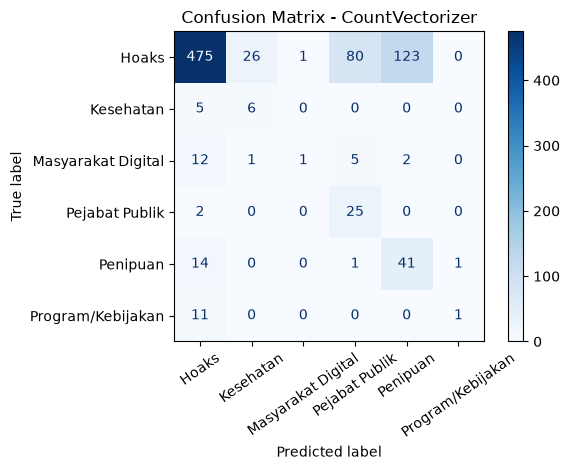

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    xticks_rotation=35,
    values_format="d",
)
plt.title("Confusion Matrix - CountVectorizer")
plt.tight_layout()
plt.show()

In [11]:
# TF-IDF memberi bobot lebih besar pada kata yang informatif.
tfidf = TfidfVectorizer(
    max_features=30000,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Bentuk data training:", X_train_tfidf.shape)
print("Bentuk data testing:", X_test_tfidf.shape)
print("Contoh fitur:", tfidf.get_feature_names_out()[:20])

Bentuk data training: (3329, 30000)
Bentuk data testing: (833, 30000)
Contoh fitur: ['00' '00 waktu' '00 wib' '000' '000 00' '000 000' '000 adalah' '000 bagi'
 '000 bergambar' '000 dalam' '000 dan' '000 dari' '000 dengan'
 '000 dollar' '000 faktanya' '000 https' '000 kali' '000 ke' '000 link'
 '000 merupakan']


In [12]:
# Latih Multinomial Naive Bayes menggunakan fitur TF-IDF.
mnb_tfidf = MultinomialNB(alpha=0.5)
mnb_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)
print("Model TF-IDF berhasil dilatih.")

Model TF-IDF berhasil dilatih.


In [13]:
acc_tfidf = accuracy_score(y_test, y_pred_tfidf)
macro_f1_tfidf = f1_score(y_test, y_pred_tfidf, average="macro", zero_division=0)
print("Akurasi TF-IDF:", round(acc_tfidf * 100, 2), "%")
print("Macro F1 TF-IDF:", round(macro_f1_tfidf, 4))
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred_tfidf, labels=labels, target_names=labels, zero_division=0))

Akurasi TF-IDF: 84.63 %
Macro F1 TF-IDF: 0.1528

Laporan klasifikasi:
                    precision    recall  f1-score   support

             Hoaks       0.85      1.00      0.92       705
         Kesehatan       0.00      0.00      0.00        11
Masyarakat Digital       0.00      0.00      0.00        21
    Pejabat Publik       0.00      0.00      0.00        27
          Penipuan       0.00      0.00      0.00        57
 Program/Kebijakan       0.00      0.00      0.00        12

          accuracy                           0.85       833
         macro avg       0.14      0.17      0.15       833
      weighted avg       0.72      0.85      0.78       833



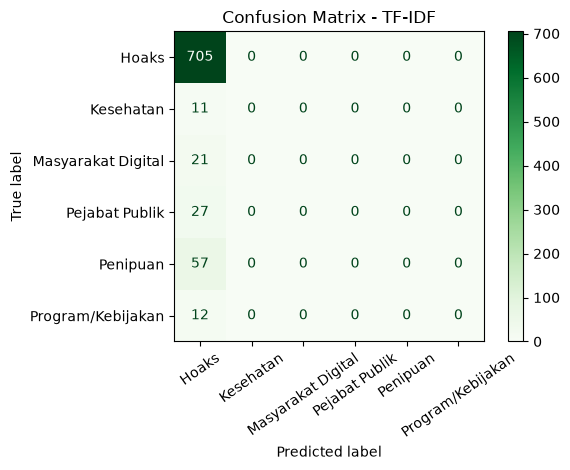

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    labels=labels,
    display_labels=labels,
    cmap="Greens",
    xticks_rotation=35,
    values_format="d",
)
plt.title("Confusion Matrix - TF-IDF")
plt.tight_layout()
plt.show()

In [15]:
# Bandingkan kedua metode dengan macro dan weighted metrics.
# Macro F1 memberi bobot setara pada setiap kelas yang tidak seimbang.
hasil_perbandingan = pd.DataFrame({
    "Metode": ["CountVectorizer", "TF-IDF"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_bow),
        accuracy_score(y_test, y_pred_tfidf),
    ],
    "Precision Macro": [
        precision_score(y_test, y_pred_bow, average="macro", zero_division=0),
        precision_score(y_test, y_pred_tfidf, average="macro", zero_division=0),
    ],
    "Recall Macro": [
        recall_score(y_test, y_pred_bow, average="macro", zero_division=0),
        recall_score(y_test, y_pred_tfidf, average="macro", zero_division=0),
    ],
    "F1 Macro": [
        f1_score(y_test, y_pred_bow, average="macro", zero_division=0),
        f1_score(y_test, y_pred_tfidf, average="macro", zero_division=0),
    ],
    "F1 Weighted": [
        f1_score(y_test, y_pred_bow, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_tfidf, average="weighted", zero_division=0),
    ],
})
display(hasil_perbandingan.round(4))

,Metode,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,CountVectorizer,0.6591,0.4282,0.4992,0.3348,0.7016
1,TF-IDF,0.8463,0.1411,0.1667,0.1528,0.7759


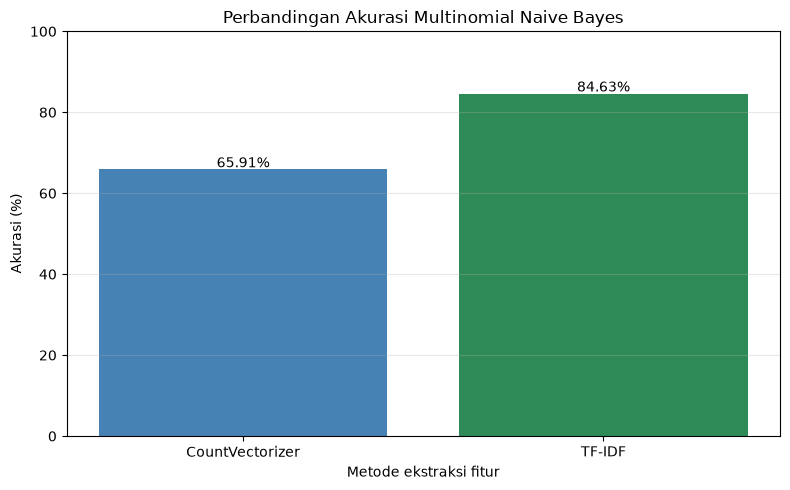

In [16]:
plt.figure(figsize=(8, 5))
plt.bar(hasil_perbandingan["Metode"], hasil_perbandingan["Accuracy"] * 100, color=["steelblue", "seagreen"])
plt.title("Perbandingan Akurasi Multinomial Naive Bayes")
plt.xlabel("Metode ekstraksi fitur")
plt.ylabel("Akurasi (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
for i, nilai in enumerate(hasil_perbandingan["Accuracy"]):
    plt.text(i, nilai * 100 + 0.5, f"{nilai * 100:.2f}%", ha="center")
plt.tight_layout()
plt.show()

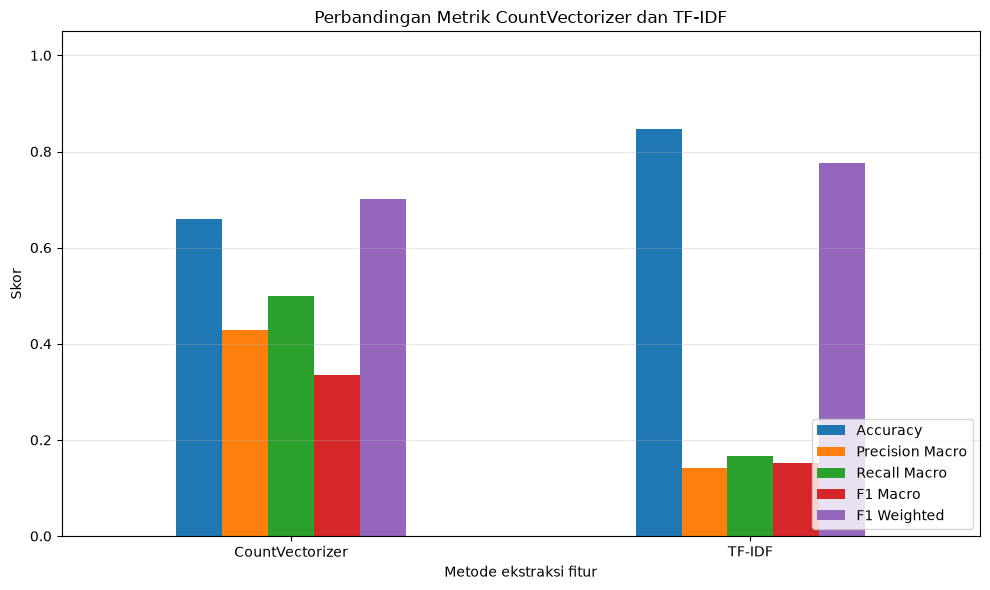

In [17]:
metrik = ["Accuracy", "Precision Macro", "Recall Macro", "F1 Macro", "F1 Weighted"]
hasil_perbandingan.set_index("Metode")[metrik].plot(kind="bar", figsize=(10, 6))
plt.title("Perbandingan Metrik CountVectorizer dan TF-IDF")
plt.xlabel("Metode ekstraksi fitur")
plt.ylabel("Skor")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
# Pilih metode berdasarkan Macro F1 agar tiap kategori diperhitungkan setara.
indeks_terbaik = hasil_perbandingan["F1 Macro"].idxmax()
metode_terbaik = hasil_perbandingan.loc[indeks_terbaik]
print("Metode terbaik berdasarkan Macro F1:")
print(metode_terbaik["Metode"])
print("Macro F1:", round(metode_terbaik["F1 Macro"], 4))
print("Akurasi:", round(metode_terbaik["Accuracy"] * 100, 2), "%")
print("F1 weighted:", round(metode_terbaik["F1 Weighted"], 4))

Metode terbaik berdasarkan Macro F1:
CountVectorizer
Macro F1: 0.3348
Akurasi: 65.91 %
F1 weighted: 0.7016
